# Decentralized & Constrained Bayesian Logistic Regression on Adult Income Data

Section 5.3 of the paper. 45,222 complete records (income > 50K vs <= 50K), standardized numerical features,
one-hot categorical features (drop-first), intercept ($d=42$). Stratified 80/20 split.
Training data split uniformly at random over $N$ agents.

Prior: $\mathcal N(0,\tau^2 I)$ restricted to the $\ell_2$-ball $\mathcal K=\{\|\beta\|\le s\}$, where
$s = 0.8\,\|\beta_{\rm sk}\|$ and $\beta_{\rm sk}$ is scikit-learn's default `LogisticRegression()` estimate
($\ell_2$ penalty, $C = 1$). We report the test accuracy and the test negative log-likelihood (NLL) of the posterior predictive
$\hat p(X)=\frac1M\sum_m\sigma(X^\top\beta_m^{(k)})$.

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "experiments" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
from src import (NETWORK_NAMES, mixing_matrix, de_psgld, psgld, w2_empirical,
                 problems, apply_style, COLORS)

apply_style()
FIG_DIR = ROOT / "figure"
FIG_DIR.mkdir(exist_ok=True)
%matplotlib inline

## Parameters

In [2]:
# problem
N      = 30
BATCH  = 32
TAU2   = 100.0      # variance of the weak Gaussian prior (gives strong convexity)
SHRINK = 0.8        # s = SHRINK * ||beta_sk||
DATA_SEED = 0       # train/test split and assignment of data to agents

# sampler
GAMMA    = 1e-5
ETA_FRAC = 0.6
N_ITER   = 800
RECORD_EVERY = 30
M        = 200      # copies of the network (posterior draws per agent)
SEED     = 1
NETWORKS = ["full", "ring", "star"]
AGENTS_TO_SHOW = [0, 4, 8]

ACC_YLIM, NLL_YLIM = (0.80, 0.86), (0.30, 0.40)
SAVE_FIGS = True

## Problem and stepsize

In [3]:
prob = problems.adult_logistic(N=N, batch=BATCH, tau2=TAU2, shrink=SHRINK, seed=DATA_SEED)
eta = ETA_FRAC * prob.eta_max(GAMMA)
eta_c = eta / N
print(f"train/test = {prob.n_train}/{prob.n_test},  d = {prob.d},  n_i = {prob.ni}")
print(f"||beta_sk|| = {np.linalg.norm(prob.beta_sk):.3f},  s = {prob.s:.3f}")
print(f"scikit-learn: test accuracy = {prob.sk_acc:.4f},  test NLL = {prob.sk_nll:.4f}")
print(f"L = {prob.L:.1f},  eta = {eta:.3e},  eta_central = {eta_c:.3e}")

train/test = 36177/9045,  d = 42,  n_i = 1205
||beta_sk|| = 2.732,  s = 2.185
scikit-learn: test accuracy = 0.8426,  test NLL = 0.3398
L = 2279.5,  eta = 6.707e-05,  eta_central = 2.236e-06


## Run

In [4]:
x0 = np.zeros((M, N, prob.d))
def record(B, k):
    Bm = B.mean(1)
    return ([prob.predictive(B[:, i]) for i in AGENTS_TO_SHOW], prob.predictive(Bm),
            np.mean(np.linalg.norm(B - Bm[:, None], axis=-1)),             # consensus error
            np.mean(np.maximum(np.linalg.norm(Bm, axis=1) - prob.s, 0)))   # distance of the mean to K

res = {}
for kind in NETWORKS:
    W, rho, _ = mixing_matrix(kind, N)
    BT, out = de_psgld(x0, W, prob.stoch_grad, prob.proj, eta, GAMMA, N_ITER, seed=SEED,
                       record=record, record_every=RECORD_EVERY, progress=NETWORK_NAMES[kind])
    res[kind] = dict(rho=rho, agents=np.array([o[0] for o in out]), mean=np.array([o[1] for o in out]),
                     cons=np.array([o[2] for o in out]), dist=np.array([o[3] for o in out]), final=BT,
                     all_agents=np.array([prob.predictive(BT[:, i]) for i in range(N)]))

BC, out_c = psgld(np.zeros((M, prob.d)), prob.stoch_grad_central, prob.proj, eta_c, GAMMA, N_ITER,
                  seed=SEED, record=lambda B, k: prob.predictive(B), record_every=RECORD_EVERY, progress="PSGLD")
pred_central = np.array(out_c)
iters = np.arange(0, N_ITER + 1, RECORD_EVERY)

  Fully Connected: 800/800 iterations (56s)
  Circular: 800/800 iterations (49s)
  Star: 800/800 iterations (48s)
  PSGLD: 800/800 iterations (54s)


## Test accuracy and test NLL vs iterations

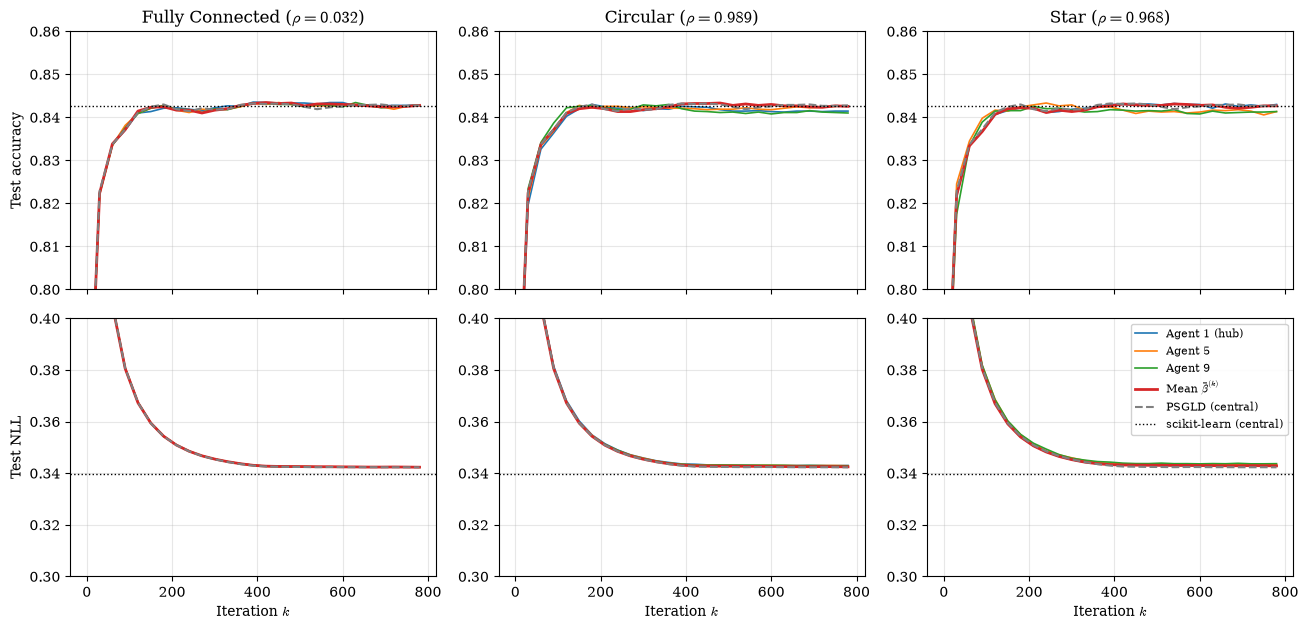

In [5]:
fig, axes = plt.subplots(2, len(NETWORKS), figsize=(4.4 * len(NETWORKS), 6.4), sharex=True, squeeze=False)
for j, kind in enumerate(NETWORKS):
    r = res[kind]
    for row, (col, ylab, ylim, ref_val) in enumerate([(0, "Test accuracy", ACC_YLIM, prob.sk_acc),
                                                      (1, "Test NLL", NLL_YLIM, prob.sk_nll)]):
        ax = axes[row, j]
        for q, i in enumerate(AGENTS_TO_SHOW):
            lab = f"Agent {i+1}" + (" (hub)" if kind == "star" and i == 0 else "")
            ax.plot(iters, r["agents"][:, q, col], color=COLORS[q], lw=1.2, label=lab)
        ax.plot(iters, r["mean"][:, col], color=COLORS[3], lw=2, label=r"Mean $\bar\beta^{(k)}$")
        ax.plot(iters, pred_central[:, col], color="gray", ls="--", lw=1.5, label="PSGLD (central)")
        ax.axhline(ref_val, color="k", ls=":", lw=1, label="scikit-learn (central)")
        ax.set_ylim(*ylim); ax.xaxis.set_major_locator(plt.MaxNLocator(5))
        if row == 0: ax.set_title(f"{NETWORK_NAMES[kind]} ($\\rho={r['rho']:.3f}$)")
        else: ax.set_xlabel("Iteration $k$")
        if j == 0: ax.set_ylabel(ylab)
axes[1, -1].legend(fontsize=8)
fig.tight_layout()
if SAVE_FIGS:
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"exp3_adult.{ext}", dpi=200, bbox_inches="tight")

## Consensus error

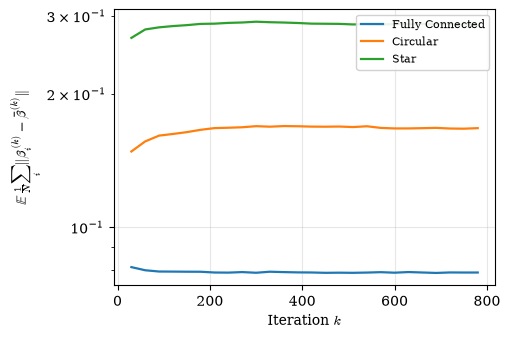

In [6]:
fig, ax = plt.subplots(figsize=(5.2, 3.5))
for j, kind in enumerate(NETWORKS):
    ax.plot(iters[1:], res[kind]["cons"][1:], color=COLORS[j], lw=1.6, label=NETWORK_NAMES[kind])
ax.set_yscale("log"); ax.set_xlabel("Iteration $k$")
ax.set_ylabel(r"$\mathbb{E}\,\frac{1}{N}\sum_i\|\beta_i^{(k)}-\bar\beta^{(k)}\|$")
ax.xaxis.set_major_locator(plt.MaxNLocator(5)); ax.legend(fontsize=8)
fig.tight_layout()
if SAVE_FIGS:
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"exp3_consensus.{ext}", dpi=200, bbox_inches="tight")

## Summary

In [7]:
rows = []
for k in NETWORKS:
    r = res[k]
    rows.append(dict(network=NETWORK_NAMES[k], rho=r["rho"], acc_mean=r["mean"][-1, 0], nll_mean=r["mean"][-1, 1],
                     acc_agents_min=r["all_agents"][:, 0].min(), acc_agents_max=r["all_agents"][:, 0].max(),
                     nll_agents_max=r["all_agents"][:, 1].max(), consensus=r["cons"][-1],
                     dist_mean_to_K=r["dist"][-1]))
rows.append(dict(network="PSGLD (central)", acc_mean=pred_central[-1, 0], nll_mean=pred_central[-1, 1]))
rows.append(dict(network="scikit-learn (central)", acc_mean=prob.sk_acc, nll_mean=prob.sk_nll))
pd.DataFrame(rows).round(4)

,network,rho,acc_mean,nll_mean,acc_agents_min,acc_agents_max,nll_agents_max,consensus,dist_mean_to_K
0,Fully Connected,0.0323,0.8428,0.3423,0.8419,0.8433,0.3424,0.0789,0.0014
1,Circular,0.9891,0.8426,0.3425,0.8408,0.8431,0.3431,0.1671,0.0001
2,Star,0.9677,0.8427,0.3429,0.8400,0.8429,0.3447,0.2860,0.0000
3,PSGLD (central),NaN,0.8428,0.3423,NaN,NaN,NaN,NaN,NaN
4,scikit-learn (central),NaN,0.8426,0.3398,NaN,NaN,NaN,NaN,NaN
